# Setup and download data: Vannan et al. 2025 (Xenium, pulmonary fibrosis)

This notebook prepares the Xenium lung dataset from [Vannan et al., 2025, *Nature Genetics*](https://doi.org/10.1038/s41588-025-02080-x) ("Spatial transcriptomics identifies molecular niche dysregulation associated with distal lung remodeling in pulmonary fibrosis") for InterScale. The data come from GEO accession [GSE250346](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE250346).

* 45 tissue cores from 35 patients (control lungs and ILD/IPF lungs) on 5 TMAs
* 1.63 M cells, 343-gene Xenium panel
* Author annotations: 49 cell types (`final_CT`), 4 lineages (`final_lineage`), 12 cell-based niches (`CNiche`) and 12 transcript-based niches (`TNiche`)

**Steps to run before this notebook**

1. Download the processed Seurat object from GEO into `data/vannan25_raw/`:
   ```
   wget https://ftp.ncbi.nlm.nih.gov/geo/series/GSE250nnn/GSE250346/suppl/GSE250346_Seurat_GSE250346_CORRECTED_SEE_RDS_README_082024.rds
   ```
   Use the `CORRECTED` object: the bioRxiv-era object had 35 swapped gene labels (see `GSE250346_RDS_README.txt`).
2. Export it to plain files. This needs only base R + `Matrix`, not Seurat:
   ```
   Rscript scripts/vannan_25/export_seurat_vannan25.R <rds> data/vannan25_raw/export
   ```

In [2]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad
import scanpy as sc
import squidpy as sq
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

#from interscale.pp import sliding_window

import warnings
warnings.filterwarnings("ignore")

In [3]:
DATA = "vannan25"
DATA_DIR = Path("/lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/data")
EXPORT_DIR = DATA_DIR / "vannan25_raw" / "export"

VANNAN_25 = DATA_DIR / "vannan25.h5ad"        # assembled, unprocessed
VANNAN_25_PP = DATA_DIR / "vannan25_pp.h5ad"  # input for InterScale

SAMPLE_KEY = "sample"
PATIENT_KEY = "patient"

## Load data

Assemble the AnnData from the R export. `counts_*.bin` is the genes x cells CSC matrix from Seurat. Read as CSR, it is directly the cells x genes matrix AnnData expects.

In [4]:
def read_sparse(prefix: str) -> sp.csr_matrix:
    n_feat, n_cells, nnz = map(int, (EXPORT_DIR / f"{prefix}_dims.txt").read_text().split())
    i = np.fromfile(EXPORT_DIR / f"{prefix}_i.bin", dtype=np.int32)
    p = np.fromfile(EXPORT_DIR / f"{prefix}_p.bin", dtype=np.int32)
    x = np.fromfile(EXPORT_DIR / f"{prefix}_x.bin", dtype=np.int32).astype(np.float32)
    assert len(i) == len(x) == nnz and len(p) == n_cells + 1
    return sp.csr_matrix((x, i, p), shape=(n_cells, n_feat))


counts = read_sparse("counts")
niche_counts = read_sparse("niche")
genes = (EXPORT_DIR / "genes.txt").read_text().splitlines()
niche_features = (EXPORT_DIR / "niche_features.txt").read_text().splitlines()

obs = pd.read_csv(EXPORT_DIR / "obs.csv", index_col=0, low_memory=False)
umap = pd.read_csv(EXPORT_DIR / "umap.csv", index_col=0)
assert (umap.index == obs.index).all()
counts.shape, niche_counts.shape, obs.shape

((1630319, 343), (1630319, 47), (1630319, 28))

Cast the annotations to categoricals. Niche labels are ordered naturally (`C1, C2, …, C12`), not lexically.

In [5]:
def natural_categories(s: pd.Series) -> pd.Categorical:
    cats = sorted(s.dropna().unique(), key=lambda v: (v[0], int(v[1:])))
    return pd.Categorical(s, categories=cats)


for col in ["CNiche", "TNiche"]:
    obs[col] = natural_categories(obs[col])

for col in ["sample", "patient", "sample_type", "sample_affect", "disease_status", "tma", "run",
            "final_CT", "final_lineage"]:
    obs[col] = obs[col].astype("category")

obs["disease_status"] = obs["disease_status"].cat.reorder_categories(["Control", "Disease"])
obs["sample_affect"] = obs["sample_affect"].cat.reorder_categories(["Unaffected", "Less Affected", "More Affected"])

In [6]:
adata = ad.AnnData(
    X=counts,
    obs=obs,
    var=pd.DataFrame(index=pd.Index(genes, name="gene")),
)
# Per-sample Xenium coordinates in µm. The adj_/super_adj_ columns only lay the cores out side by
# side for plotting.
adata.obsm["spatial"] = adata.obs[["x_centroid", "y_centroid"]].to_numpy()
adata.obsm["X_umap"] = umap.to_numpy()
# Neighbourhood cell-type composition from the authors' "niche" assay (columns = final_CT labels),
# the input from which they clustered CNiche.
adata.obsm["niche_composition"] = niche_counts
adata.uns["niche_composition_features"] = np.array(niche_features)
adata

AnnData object with n_obs × n_vars = 1630319 × 343
    obs: 'sample', 'patient', 'cell_id', 'full_cell_id', 'sample_type', 'sample_affect', 'disease_status', 'percent_pathology', 'tma', 'run', 'final_CT', 'final_lineage', 'CNiche', 'TNiche', 'lumen_id', 'lumen_rank', 'x_centroid', 'y_centroid', 'adj_x_centroid', 'adj_y_centroid', 'super_adj_x_centroid', 'super_adj_y_centroid', 'nCount_RNA', 'nFeature_RNA', 'perc_negcontrolprobe', 'perc_negcontrolcodeword', 'perc_unassigned', 'perc_negcontrolorunassigned'
    uns: 'niche_composition_features'
    obsm: 'spatial', 'X_umap', 'niche_composition'
    layers: None (.X)

In [7]:
adata.write(VANNAN_25)

## Sample (patient) information

Each `sample` is one tissue core and each `patient` is one donor. Nine patients contributed more than one core: TILD117 has three, and VUHD116 has two control cores (A/B). Any split must therefore be made at the **patient** level so that cores from the same donor never end up in different splits.

* `disease_status`: Control / Disease (ILD)
* `sample_type`: Unaffected (control), or the ILD sample category from the paper: `INT`, `LF`, `MF`
* `sample_affect`: Unaffected / Less Affected / More Affected (the `LA`/`MA` suffix of the sample name)
* `percent_pathology`: pathologist-estimated % of the core showing pathology

`sample_type` and `sample_affect` are separate annotations, and for ILD cores they do not map onto each other (e.g. `TILD028LA` is `MF` but `Less Affected`). Pick one deliberately when using either as a label.

In [8]:
sample_cols = ["patient", "disease_status", "sample_type", "sample_affect", "percent_pathology", "tma", "run"]
sample_info = (
    adata.obs.groupby(SAMPLE_KEY, observed=True)[sample_cols].first()
    .join(adata.obs.groupby(SAMPLE_KEY, observed=True).size().rename("n_cells"))
    .sort_values(["disease_status", "patient", "sample_type"])
)
# The patient-level metadata must be constant within each sample
assert (adata.obs.groupby(SAMPLE_KEY, observed=True)[sample_cols].nunique() == 1).all().all()
adata.uns["sample_info"] = sample_info.reset_index().astype({c: str for c in sample_info.select_dtypes("category").columns} | {SAMPLE_KEY: str})
sample_info

,patient,disease_status,sample_type,sample_affect,percent_pathology,tma,run,n_cells
sample,,,,,,,,
THD0008,THD0008,Control,Unaffected,Unaffected,0,TMA3,Run2,69227
THD0011,THD0011,Control,Unaffected,Unaffected,20,TMA4,Run2,25364
VUHD038,VUHD038,Control,Unaffected,Unaffected,5,TMA5,Run3,5941
VUHD049,VUHD049,Control,Unaffected,Unaffected,0,TMA5,Run3,22688
VUHD069,VUHD069,Control,Unaffected,Unaffected,0,TMA2,Run1,19976
VUHD090,VUHD090,Control,Unaffected,Unaffected,5,TMA5,Run3,16110
VUHD095,VUHD095,Control,Unaffected,Unaffected,0,TMA2,Run1,11442
VUHD113,VUHD113,Control,Unaffected,Unaffected,0,TMA2,Run1,12870
VUHD116A,VUHD116,Control,Unaffected,Unaffected,0,TMA1,Run1,12372


In [8]:
print(sample_info.groupby("disease_status", observed=True).agg(n_samples=("patient", "size"), n_patients=("patient", "nunique"), n_cells=("n_cells", "sum")))
print()
print(pd.crosstab(sample_info["sample_type"], sample_info["disease_status"]))

                n_samples  n_patients  n_cells
disease_status                                
Control                10           9   225137
Disease                35          26  1405182

disease_status  Control  Disease
sample_type                     
INT                   0        8
LF                    0       13
MF                    0       14
Unaffected           10        0


## Cell types

The author annotation `final_CT` has 49 cell types grouped into 4 lineages (`final_lineage`). The UMAP below is the published one from the Seurat object.

In [9]:
ct_counts = adata.obs.groupby(["final_lineage", "final_CT"], observed=True).size().rename("n_cells").reset_index()
ct_counts.sort_values(["final_lineage", "n_cells"], ascending=[True, False]).reset_index(drop=True)

,final_lineage,final_CT,n_cells
0,Endothelial,Capillary,136727
1,Endothelial,Venous,98021
2,Endothelial,Lymphatic,13537
3,Endothelial,Arteriole,9254
4,Epithelial,AT2,100277
5,Epithelial,Multiciliated,47058
6,Epithelial,Basal,37025
7,Epithelial,AT1,24983
8,Epithelial,Transitional AT2,23580
9,Epithelial,RASC,18337


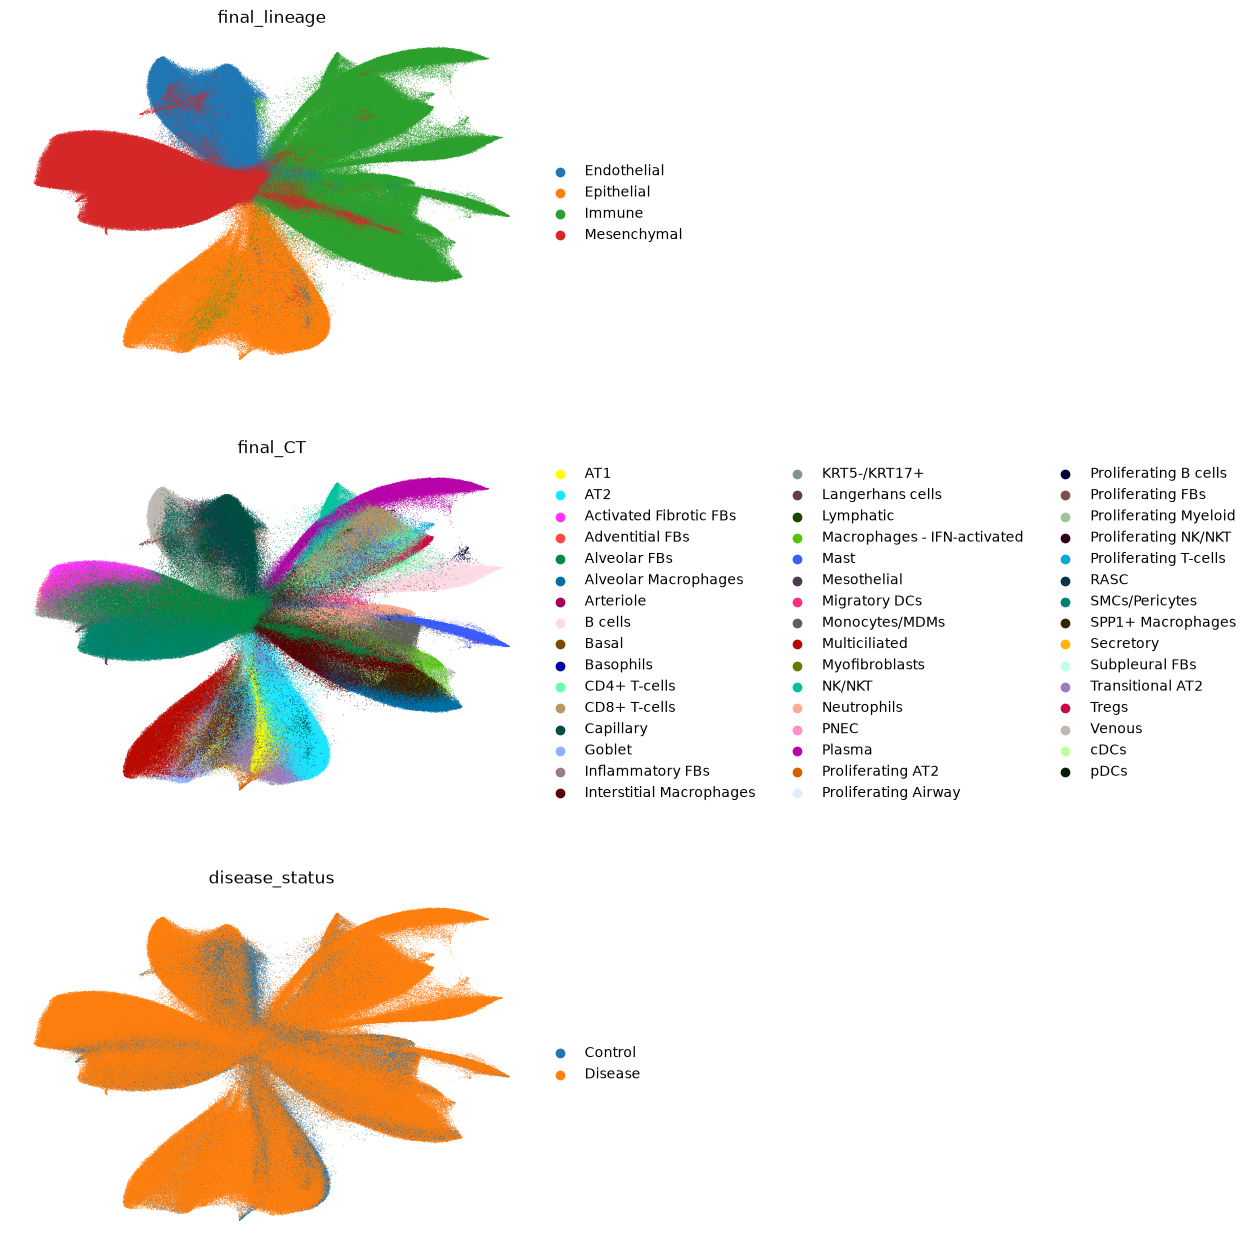

In [10]:
sc.pl.umap(adata, color=["final_lineage", "final_CT", "disease_status"], ncols=1, size=1, frameon=False)

## Niches

The authors provide two niche annotations:

* `CNiche` (**cell-based**): k-means clusters of each cell's neighbourhood cell-type composition, stored here in `obsm["niche_composition"]`.
* `TNiche` (**transcript-based**): clusters of cell-free, transcript-level GraphSAGE embeddings, assigned to cells.

The paper's names for the niches are not stored in the object. To help interpret them, the table lists the three most frequent cell types per niche.

In [11]:
def top_cell_types(niche_key: str, n: int = 3) -> pd.DataFrame:
    frac = pd.crosstab(adata.obs[niche_key], adata.obs["final_CT"], normalize="index")
    return pd.DataFrame({
        "n_cells": adata.obs[niche_key].value_counts().reindex(frac.index),
        "top_cell_types": [
            ", ".join(f"{ct} ({v:.0%})" for ct, v in row.nlargest(n).items()) for _, row in frac.iterrows()
        ],
    })


top_cell_types("CNiche")

,n_cells,top_cell_types
CNiche,,
C1,147489,"Multiciliated (31%), Basal (19%), Goblet (11%)"
C2,51897,"Transitional AT2 (24%), AT2 (15%), Alveolar FB..."
C3,262840,"Alveolar FBs (20%), Interstitial Macrophages (..."
C4,356577,"Alveolar FBs (21%), Venous (16%), Plasma (12%)"
C5,36068,"AT2 (16%), Capillary (14%), Alveolar FBs (11%)"
C6,49478,"Alveolar FBs (14%), CD4+ T-cells (12%), Inters..."
C7,41072,"CD4+ T-cells (13%), Alveolar FBs (12%), Inters..."
C8,357079,"Capillary (24%), AT2 (16%), Alveolar FBs (11%)"
C9,155143,"CD4+ T-cells (23%), B cells (19%), CD8+ T-cell..."


In [12]:
top_cell_types("TNiche")

,n_cells,top_cell_types
TNiche,,
T1,80185,"Plasma (76%), Alveolar FBs (7%), CD4+ T-cells ..."
T2,182695,"CD4+ T-cells (35%), CD8+ T-cells (23%), B cell..."
T3,102804,"Basal (20%), AT2 (17%), RASC (15%)"
T4,270718,"Capillary (40%), Alveolar FBs (11%), Neutrophi..."
T5,215710,"Interstitial Macrophages (38%), Monocytes/MDMs..."
T6,127897,"Alveolar FBs (42%), Activated Fibrotic FBs (32..."
T7,79168,"Multiciliated (53%), Goblet (19%), Basal (16%)"
T8,68289,"Alveolar Macrophages (35%), SPP1+ Macrophages ..."
T9,237069,"Alveolar FBs (38%), Mast (12%), SMCs/Pericytes..."


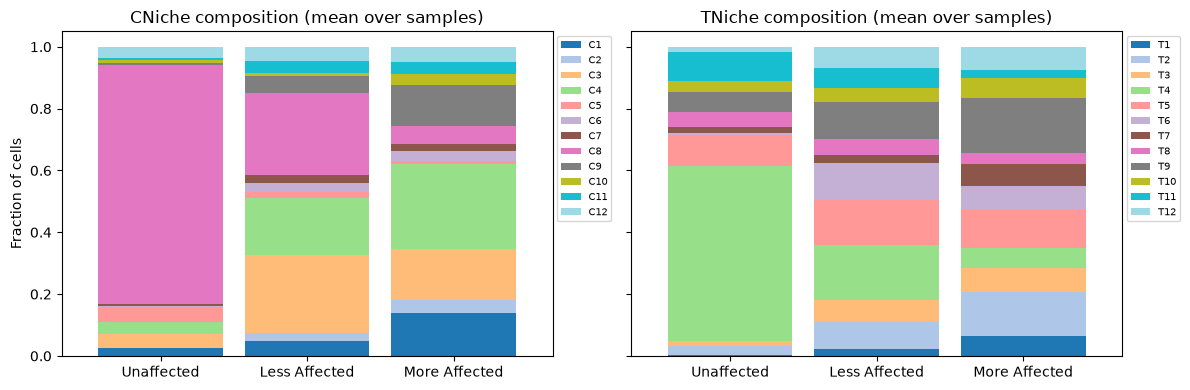

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, niche_key in zip(axes, ["CNiche", "TNiche"]):
    pd.crosstab(adata.obs[SAMPLE_KEY], adata.obs[niche_key], normalize="index").join(
        sample_info[["sample_affect"]]
    ).groupby("sample_affect", observed=True).mean().plot(kind="bar", stacked=True, ax=ax, width=0.85, cmap="tab20", legend=False)
    ax.set_title(f"{niche_key} composition (mean over samples)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(bbox_to_anchor=(1.0, 1.0), loc="upper left", fontsize=7, ncols=1)
axes[0].set_ylabel("Fraction of cells")
plt.tight_layout()
plt.show()

Spatial view of one control core and one more-affected ILD core:

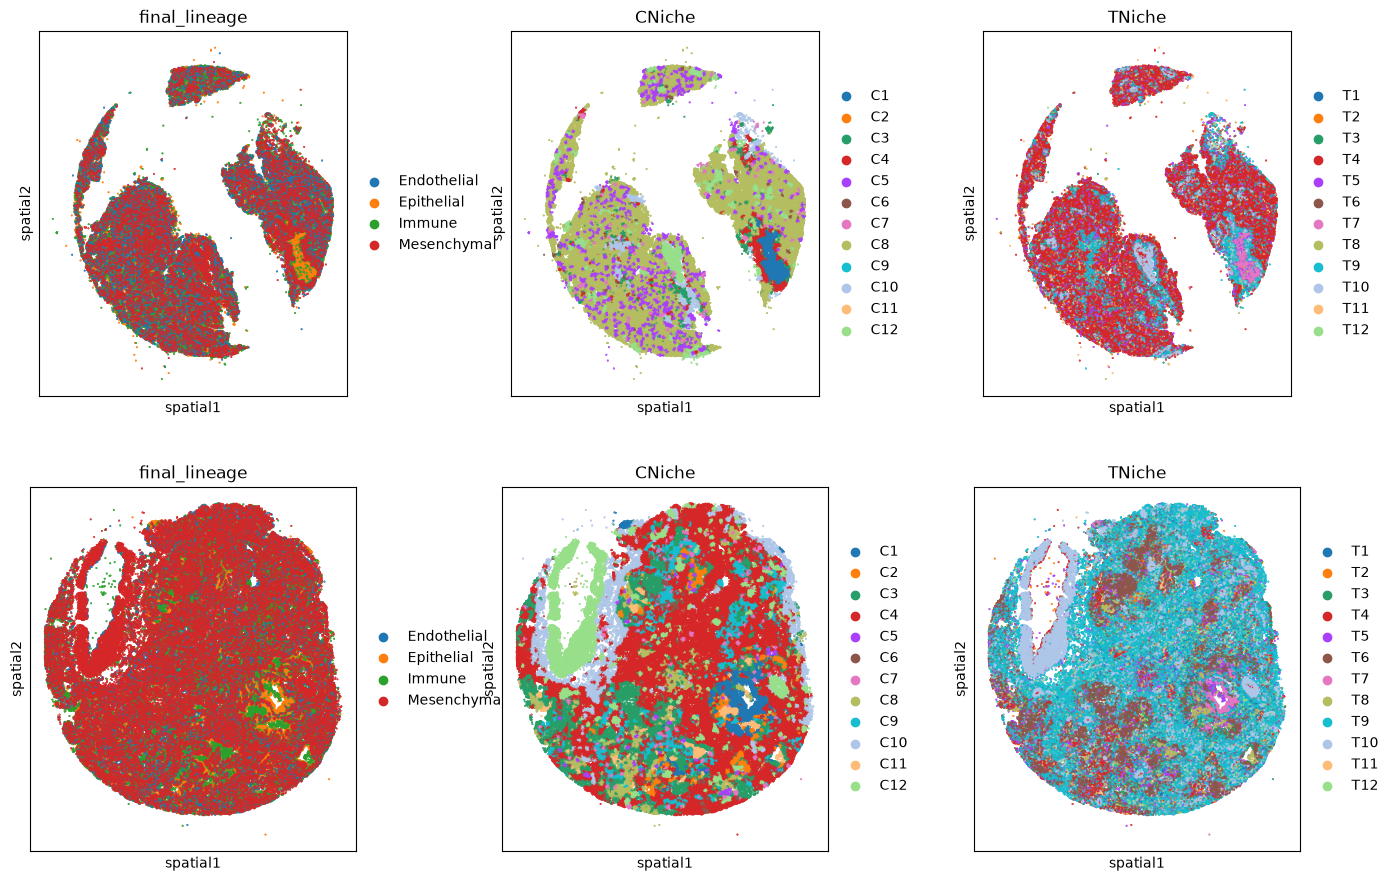

In [14]:
example_samples = [
    sample_info.query("disease_status == 'Control'")["n_cells"].idxmax(),
    sample_info.query("sample_affect == 'More Affected'")["n_cells"].idxmax(),
]
adata_ex = adata[adata.obs[SAMPLE_KEY].isin(example_samples)].copy()
sq.pl.spatial_scatter(
    adata_ex,
    library_key=SAMPLE_KEY,
    color=["final_lineage", "CNiche", "TNiche"],
    shape=None,
    size=0.5,
    figsize=(5, 5),
    ncols=3,
)

## 1. Normalization

InterScale needs normalized expression. The Seurat object holds raw integer Xenium counts:

In [15]:
print(f"Min count: {adata.X.min()}, Max count: {adata.X.max()}, integer: {np.all(adata.X.data == np.round(adata.X.data))}")
print(adata.obs[["nCount_RNA", "nFeature_RNA"]].describe().round(1))

Min count: 0.0, Max count: 70.0, integer: True
       nCount_RNA  nFeature_RNA
count   1630319.0     1630319.0
mean         74.7          36.4
std          49.9          16.2
min          12.0          10.0
25%          37.0          24.0
50%          63.0          35.0
75%         100.0          47.0
max         775.0         137.0


The cells were already QC-filtered by the authors, so no cells are removed here. All 343 panel genes are kept: with a targeted panel, HVG selection would drop curated markers. Raw counts are kept in `layers["counts"]` and the shifted logarithm in `layers["log1p_norm"]`, as for chen22.

In [16]:
adata.layers["counts"] = adata.X.copy()
scaled_counts = sc.pp.normalize_total(adata, target_sum=None, inplace=False)
adata.layers["log1p_norm"] = sc.pp.log1p(scaled_counts["X"], copy=True)
print(f'Min: {adata.layers["log1p_norm"].min()}, Max: {adata.layers["log1p_norm"].max()}')

Min: 0.0, Max: 3.705408811569214


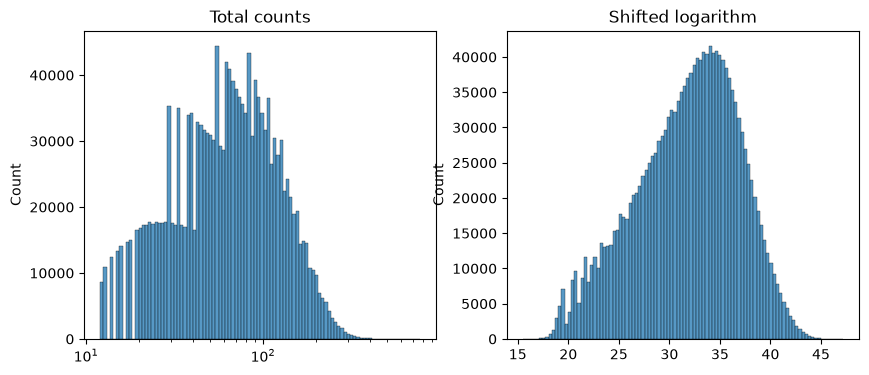

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(np.asarray(adata.layers["counts"].sum(1)).ravel(), bins=100, ax=axes[0], log_scale=(True, False))
axes[0].set_title("Total counts")
sns.histplot(np.asarray(adata.layers["log1p_norm"].sum(1)).ravel(), bins=100, ax=axes[1])
axes[1].set_title("Shifted logarithm")
plt.show()

## 2. Calculate spatial connectivity matrix

Xenium coordinates are in µm, so use a `generic` radius graph, computed per core (`library_key="sample"`). Lung parenchyma is sparse (alveolar air space). A 30 µm radius gives about 19 neighbours per cell, close to the ~21 of the ovarian Xenium config. InterScale rebuilds this graph per `sample_key` in `prepare_geome_dataset`, so this step only checks the radius. The graph is not saved, which keeps the h5ad small.

In [18]:
RADIUS = 30
sq.gr.spatial_neighbors(adata, coord_type="generic", radius=RADIUS, library_key=SAMPLE_KEY)
n_neighs = np.diff(adata.obsp["spatial_connectivities"].indptr)
print(f"radius {RADIUS} µm: mean {n_neighs.mean():.1f}, median {np.median(n_neighs):.0f} neighbours/cell, "
      f"{(n_neighs == 0).mean():.2%} isolated cells")
pd.Series(n_neighs, index=adata.obs_names).groupby(adata.obs[SAMPLE_KEY], observed=True).mean().describe().round(1)

INFO     Creating graph using `None` transform and `45` libraries.                                                 


radius 30 µm: mean 18.1, median 17 neighbours/cell, 0.18% isolated cells


count    45.0
mean     16.6
std       4.1
min       5.5
25%      13.7
50%      17.3
75%      19.0
max      24.0
dtype: float64

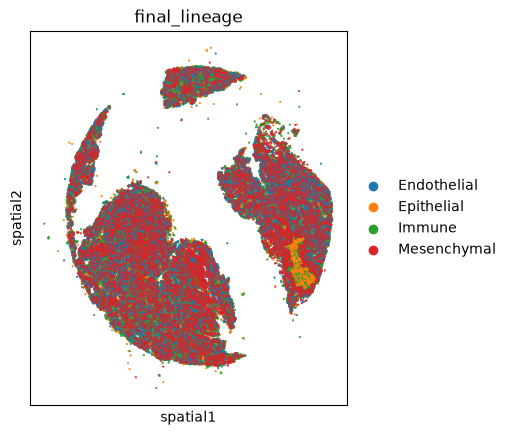

In [19]:
sq.pl.spatial_scatter(
    adata_ex[adata_ex.obs[SAMPLE_KEY] == example_samples[0]],
    library_key=SAMPLE_KEY,
    color="final_lineage",
    shape=None,
    size=0.5,
    figsize=(5, 5),
)
del adata.obsp["spatial_connectivities"], adata.obsp["spatial_distances"], adata.uns["spatial_neighbors"]

## 3. Calculate sliding windows

Cores have about 6k–125k cells, far above the transformer's context length, so each core is cut into non-overlapping 500 µm windows. Border windows with fewer than half the median number of cells are merged into the nearest full window (`partial_window="merge"`).

In [20]:
cells_per_sample = adata.obs.groupby(SAMPLE_KEY, observed=True).size()
print(f"Cells per sample: Min: {cells_per_sample.min()}, Max: {cells_per_sample.max()}, Avg: {cells_per_sample.mean():.0f}")

Cells per sample: Min: 5941, Max: 124717, Avg: 36229


In [21]:
WINDOW_SIZE = 500  # µm

sliding_window(
    adata,
    library_key=SAMPLE_KEY,
    coord_columns=("x_centroid", "y_centroid"),
    window_size=WINDOW_SIZE,
    split_line=None,
    partial_window="merge",
    sliding_window_key="sliding_window_assignment",
)
adata.obs["sliding_window_assignment"] = adata.obs["sliding_window_assignment"].astype(str).astype("category")

1773 windows; cells per window: Min: 11, Max: 2817, Mean: 920, Median: 873
-> set model.global_component.parameters.max_seq_len >= 2817


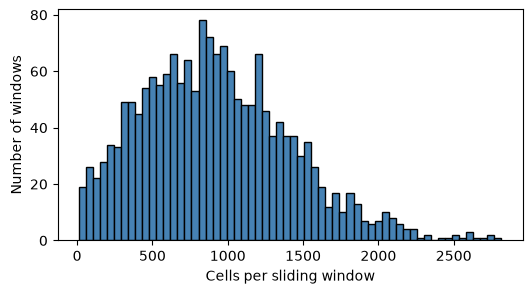

In [22]:
# Each window must lie within one sample
assert (adata.obs.groupby("sliding_window_assignment", observed=True)[SAMPLE_KEY].nunique() == 1).all()

window_sizes = adata.obs.groupby("sliding_window_assignment", observed=True).size()
print(f"{len(window_sizes)} windows; cells per window: Min: {window_sizes.min()}, Max: {window_sizes.max()}, "
      f"Mean: {window_sizes.mean():.0f}, Median: {window_sizes.median():.0f}")
print(f"-> set model.global_component.parameters.max_seq_len >= {window_sizes.max()}")

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(window_sizes, bins=60, color="steelblue", edgecolor="black")
ax.set_xlabel("Cells per sliding window")
ax.set_ylabel("Number of windows")
plt.show()

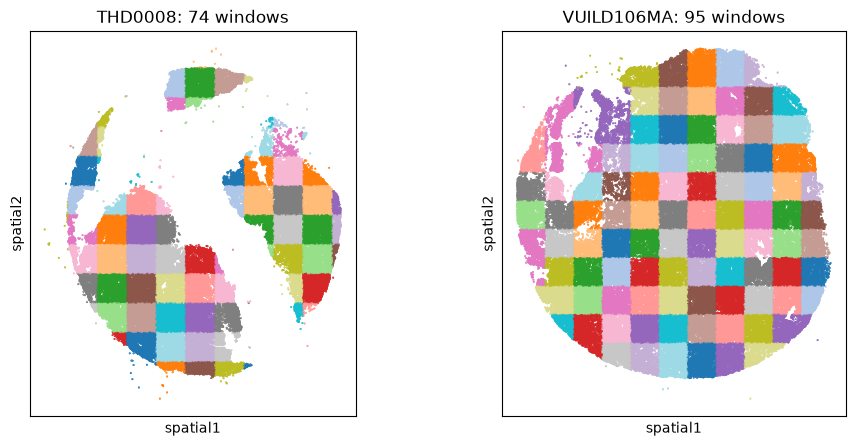

In [23]:
adata_ex = adata[adata.obs[SAMPLE_KEY].isin(example_samples)].copy()
# Too many windows for one categorical palette: cycle 20 colours over the windows of these samples
window_codes = adata_ex.obs["sliding_window_assignment"].cat.remove_unused_categories().cat.codes
adata_ex.obs["window_colour"] = pd.Categorical((window_codes % 20).astype(str))
adata_ex.uns["window_colour_colors"] = list(plt.get_cmap("tab20").colors)
sq.pl.spatial_scatter(
    adata_ex,
    library_key=SAMPLE_KEY,
    color="window_colour",
    shape=None,
    size=0.5,
    figsize=(5, 5),
    legend_loc=None,
    title=[f"{s}: {adata_ex.obs.loc[adata_ex.obs[SAMPLE_KEY] == s, 'sliding_window_assignment'].nunique()} windows" for s in example_samples],
)

## 4. Split data into train, val and test set

Splits are made at the **patient** level and stratified by `disease_status`, so a donor's cores and windows all fall in one split. About 15% of patients per class go to val, 15% to test (at least one per class), and the rest to train.

In [24]:
SEED = 0
VAL_FRAC = TEST_FRAC = 0.15

patient_status = adata.obs.groupby(PATIENT_KEY, observed=True)["disease_status"].first()
assert (adata.obs.groupby(PATIENT_KEY, observed=True)["disease_status"].nunique() == 1).all()

rng = np.random.default_rng(SEED)
split_map = {}
for status, patients in patient_status.groupby(patient_status, observed=True):
    patients = rng.permutation(patients.index.to_numpy())
    n_val = max(1, round(VAL_FRAC * len(patients)))
    n_test = max(1, round(TEST_FRAC * len(patients)))
    split_map |= {p: "val" for p in patients[:n_val]}
    split_map |= {p: "test" for p in patients[n_val:n_val + n_test]}
    split_map |= {p: "train" for p in patients[n_val + n_test:]}

adata.obs["split"] = pd.Categorical(adata.obs[PATIENT_KEY].map(split_map), categories=["train", "val", "test"])
assert adata.obs["split"].notna().all()
assert (adata.obs.groupby(PATIENT_KEY, observed=True)["split"].nunique() == 1).all()

In [25]:
summary = adata.obs.groupby(["split", "disease_status"], observed=True).agg(
    n_patients=(PATIENT_KEY, "nunique"),
    n_samples=(SAMPLE_KEY, "nunique"),
    n_windows=("sliding_window_assignment", "nunique"),
    n_cells=(SAMPLE_KEY, "size"),
)
summary

n_patients  n_samples  n_windows  n_cells
split disease_status                                           
train Control                  7          8        273   189051
      Disease                 18         24       1007  1020075
val   Control                  1          1         25    19976
      Disease                  4          6        280   273831
test  Control                  1          1         31    16110
      Disease                  4          5        157   111276

In [26]:
adata.obs.groupby("split", observed=True)[PATIENT_KEY].unique().apply(sorted).to_frame()

,patient
split,
train,"[THD0008, THD0011, TILD111, TILD117, TILD130, ..."
val,"[TILD080, VUHD069, VUILD102, VUILD106, VUILD91]"
test,"[TILD028, TILD049, TILD113, VUHD090, VUILD48]"


## Save adata object

Save the prepared object so it can be loaded for model training. `X` stays as raw counts, and the config points InterScale to the `log1p_norm` layer.

In [27]:
adata.obs = adata.obs.drop(columns=["X", "Y"], errors="ignore")
adata.write(VANNAN_25_PP)
adata

AnnData object with n_obs × n_vars = 1630319 × 343
    obs: 'sample', 'patient', 'cell_id', 'full_cell_id', 'sample_type', 'sample_affect', 'disease_status', 'percent_pathology', 'tma', 'run', 'final_CT', 'final_lineage', 'CNiche', 'TNiche', 'lumen_id', 'lumen_rank', 'x_centroid', 'y_centroid', 'adj_x_centroid', 'adj_y_centroid', 'super_adj_x_centroid', 'super_adj_y_centroid', 'nCount_RNA', 'nFeature_RNA', 'perc_negcontrolprobe', 'perc_negcontrolcodeword', 'perc_unassigned', 'perc_negcontrolorunassigned', 'sliding_window_assignment', 'split'
    uns: 'niche_composition_features', 'sample_info', 'final_lineage_colors', 'final_CT_colors', 'disease_status_colors'
    obsm: 'spatial', 'X_umap', 'niche_composition'
    layers: None (.X), 'counts', 'log1p_norm'

## Prepare config file

Add a dataset config, e.g. `interscale/config_files/datasets/vannan25.yaml`, following the other dataset configs. Take `max_seq_len` from the sliding-window statistics above:

```yaml
model:
  global_component:
    parameters:
      max_seq_len: <max cells per window, see section 3>
  save: /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/vannan25/
dataset:
  h5ad_data: /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/data/vannan25_pp.h5ad
  name: vannan25
  layer_key: log1p_norm
  sample_key: [sliding_window_assignment]
  split_key: split
  spatial_neigbors_kwargs:
    radius: 30
    coord_type: generic
    library_key: sliding_window_assignment
```

Candidate prediction targets: `final_CT` / `final_lineage` / `CNiche` / `TNiche` (node level), or `disease_status` / `sample_affect` (graph level).